<a href="https://colab.research.google.com/github/rubioslava/sprint4-ecommerce-eda/blob/main/sprint4_final_project_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sprint 4 Project: E-Commerce Customer Behavior EDA

Welcome to your Sprint 4 final project. In this project, you will apply everything you've learned across Sprints 1–4 to perform a complete Exploratory Data Analysis on the **Olist Brazilian E-Commerce dataset** — real data from a real e-commerce platform.


## Dataset

You'll work with 7 CSV files from the Olist e-commerce dataset:

| File | Rows | Description |
|---|---|---|
| `olist_orders_dataset.csv` | 99,441 | Orders with timestamps and status |
| `olist_order_items_dataset.csv` | 112,650 | Items per order with price and freight |
| `olist_customers_dataset.csv` | 99,441 | Customer ID, city, state |
| `olist_products_dataset.csv` | 32,951 | Products with category and dimensions |
| `olist_order_reviews_dataset.csv` | 99,224 | Review scores (1–5 stars) |
| `olist_order_payments_dataset.csv` | 103,886 | Payment type and value |
| `product_category_name_translation.csv` | 71 | Portuguese → English category names |

Let's get started!

---

## Setup

Run the cells below to import the libraries you'll need and load the datasets. The data is hosted on GitHub, so you can load it with one line of code per file — no uploads required.

In [43]:
# Import libraries
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

# Confirm versions
print(f"pandas version: {pd.__version__}")
print("Setup complete!")

pandas version: 2.2.3
Setup complete!


In [44]:
# Load the 7 datasets from the curriculum GitHub repo
BASE_URL = 'https://practicum-content.s3.us-west-1.amazonaws.com/data-analytics/eda-project/'

orders = pd.read_csv(BASE_URL + 'olist_orders_dataset.csv')
items = pd.read_csv(BASE_URL + 'olist_order_items_dataset.csv')
customers = pd.read_csv(BASE_URL + 'olist_customers_dataset.csv')
products = pd.read_csv(BASE_URL + 'olist_products_dataset.csv')
reviews = pd.read_csv(BASE_URL + 'olist_order_reviews_dataset.csv')
payments = pd.read_csv(BASE_URL + 'olist_order_payments_dataset.csv')
translation = pd.read_csv(BASE_URL + 'product_category_name_translation.csv')

print(f"orders:      {orders.shape}")
print(f"items:       {items.shape}")
print(f"customers:   {customers.shape}")
print(f"products:    {products.shape}")
print(f"reviews:     {reviews.shape}")
print(f"payments:    {payments.shape}")
print(f"translation: {translation.shape}")

orders:      (99441, 8)
items:       (112650, 7)
customers:   (99441, 5)
products:    (32951, 9)
reviews:     (99224, 7)
payments:    (103886, 5)
translation: (71, 2)


In [45]:
# Set up an in-memory SQLite database with all 7 tables
# This lets you run SQL queries directly against the DataFrames
conn = sqlite3.connect(':memory:')

orders.to_sql('orders', conn, index=False, if_exists='replace')
items.to_sql('items', conn, index=False, if_exists='replace')
customers.to_sql('customers', conn, index=False, if_exists='replace')
products.to_sql('products', conn, index=False, if_exists='replace')
reviews.to_sql('reviews', conn, index=False, if_exists='replace')
payments.to_sql('payments', conn, index=False, if_exists='replace')
translation.to_sql('translation', conn, index=False, if_exists='replace')

print("SQLite database ready. You can now run SQL queries with pd.read_sql().")

SQLite database ready. You can now run SQL queries with pd.read_sql().


---

## Question 1: Inspect the orders DataFrame

**Your task:** For the `orders` DataFrame:
1. Print its shape
2. Print the first 5 rows with `.head()`
3. Print column info with `.info()`

This is the very first thing every analyst does with a new dataset.

*Skills: Sprint 4 Ch 01 (Pandas inspection)*

In [46]:
print("Shape:", orders.shape)

print("\nFirst 5 rows:")
display(orders.head())

print("\nColumn information:")
orders.info()



Shape: (99441, 8)

First 5 rows:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00



Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


---

## Question 2: Clean the orders data

The `orders` DataFrame has timestamp columns stored as strings, and a few have missing values.

**Your task:**
1. Use `.isnull().sum()` to count missing values in each column of `orders`
2. Convert `order_purchase_timestamp` and `order_delivered_customer_date` to datetime using `pd.to_datetime()`
3. Print the dtypes after conversion to verify

*Skills: Sprint 4 Ch 02 (Cleaning, dtype conversion)*

In [47]:
# 1. Count missing values
print("Missing values:")
print(orders.isnull().sum())

# 2. Convert columns to datetime
orders['order_purchase_timestamp'] = pd.to_datetime(
orders['order_purchase_timestamp']
)

orders['order_delivered_customer_date'] = pd.to_datetime(
orders['order_delivered_customer_date']
)

# 3. Verify data types
print("\nData types after conversion:")
print(orders.dtypes)



Missing values:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Data types after conversion:
order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                        object
order_delivered_carrier_date             object
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date            object
dtype: object


---

## Question 3: Order status breakdown (SQL)

**Your task:** Write a SQL query against the `orders` table that returns:
- `order_status`
- `num_orders` — count of orders with that status
- `pct` — percentage of total orders, rounded to 2 decimals

Sort by `num_orders` descending. Save the result to a DataFrame called `status_summary` and print it.

**Hint:** Use `pd.read_sql("...", conn)`. The percentage trick is `COUNT(*) * 100.0 / (SELECT COUNT(*) FROM orders)`.

*Skills: Sprint 2 (SQL aggregation), Sprint 4 Ch 03 (Descriptive stats)*

In [48]:
query = """
SELECT
order_status,
COUNT(*) AS num_orders,
ROUND(
COUNT(*) * 100.0 / (SELECT COUNT(*) FROM orders),
2
) AS pct
FROM orders
GROUP BY order_status
ORDER BY num_orders DESC
"""

status_summary = pd.read_sql(query, conn)

display(status_summary)



,order_status,num_orders,pct
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


---

## Question 4: Top 10 highest-revenue orders (SQL JOIN)

Each order can have multiple items. Total order revenue = sum of `price + freight_value` across all its items.

**Your task:** Write a SQL query that JOINs `orders` and `items` to find the **10 highest-revenue orders**. Return:
- `order_id`
- `order_status`
- `total_revenue` — rounded to 2 decimals

Save the result to `top_orders` and print it.

*Skills: Sprint 2 (SQL JOIN, GROUP BY), Sprint 4 Ch 06 (combining tables)*

In [49]:
query = """
SELECT
o.order_id,
o.order_status,
ROUND(SUM(i.price + i.freight_value), 2) AS total_revenue
FROM orders AS o
JOIN items AS i
ON o.order_id = i.order_id
GROUP BY o.order_id, o.order_status
ORDER BY total_revenue DESC
LIMIT 10
"""

top_orders = pd.read_sql(query, conn)

display(top_orders)

,order_id,order_status,total_revenue
0,03caa2c082116e1d31e67e9ae3700499,delivered,13664.08
1,736e1922ae60d0d6a89247b851902527,delivered,7274.88
2,0812eb902a67711a1cb742b3cdaa65ae,delivered,6929.31
3,fefacc66af859508bf1a7934eab1e97f,delivered,6922.21
4,f5136e38d1a14a4dbd87dff67da82701,delivered,6726.66
5,2cc9089445046817a7539d90805e6e5a,delivered,6081.54
6,a96610ab360d42a2e5335a3998b4718a,delivered,4950.34
7,b4c4b76c642808cbe472a32b86cddc95,canceled,4809.44
8,199af31afc78c699f0dbf71fb178d4d4,delivered,4764.34
9,8dbc85d1447242f3b127dda390d56e19,delivered,4681.78


---

## Question 5: English product categories (pandas merge)

The `products` table has a Portuguese category column called `product_category_name`. The `translation` table maps each Portuguese name to its English equivalent.

**Your task:**
1. Use `products.merge(translation, on='product_category_name', how='left')` to add the English column. Save it to `products_eng`.
2. Find the **top 10 categories by number of products** using `value_counts()` on the `product_category_name_english` column. Save to `top_categories` and print it.

*Skills: Sprint 4 Ch 06 (pandas merge), Ch 03 (value_counts)*

In [50]:
# Merge products with English translations
products_eng = products.merge(
translation,
on='product_category_name',
how='left'
)

# Find the top 10 product categories
top_categories = products_eng[
'product_category_name_english'
].value_counts().head(10)

print(top_categories)

product_category_name_english
bed_bath_table           3029
sports_leisure           2867
furniture_decor          2657
health_beauty            2444
housewares               2335
auto                     1900
computers_accessories    1639
toys                     1411
watches_gifts            1329
telephony                1134
Name: count, dtype: int64


---

## Question 6: Revenue and average review score by category

Now you'll combine three tables and compute multiple metrics per category.

**Your task:**
1. Build a DataFrame that merges `items` with `products_eng` (to get categories), then merges with `reviews` (to get scores). The shared key chain is: `items.product_id → products_eng.product_id` and `items.order_id → reviews.order_id`.
2. Add a `revenue` column = `price + freight_value`
3. Group by `product_category_name_english` and aggregate:
   - `total_revenue` = sum of `revenue`
   - `avg_review` = mean of `review_score`
   - `n_items` = count of `order_id`
4. Sort by `total_revenue` descending and show the **top 10 categories**. Save to `category_summary`.

*Skills: Sprint 4 Ch 06 (multi-table merge, groupby with multiple aggregations)*

In [51]:
# Keep one review score per order
reviews_unique = (
reviews.groupby('order_id', as_index=False)
['review_score'].mean()
)

# Merge items with product categories
df = items.merge(
products_eng,
on='product_id',
how='left'
)

# Merge with unique order reviews
df = df.merge(
reviews_unique,
on='order_id',
how='left'
)

# Calculate revenue per item
df['revenue'] = df['price'] + df['freight_value']

# Aggregate by category
category_summary = (
df.groupby('product_category_name_english')
.agg(
total_revenue=('revenue', 'sum'),
avg_review=('review_score', 'mean'),
n_items=('order_id', 'count')
)
.sort_values('total_revenue', ascending=False)
.head(10)
.round(2)
)

display(category_summary)





,total_revenue,avg_review,n_items
product_category_name_english,,,
health_beauty,1441248.07,4.14,9670
watches_gifts,1305541.61,4.02,5991
bed_bath_table,1241681.72,3.90,11115
sports_leisure,1156656.48,4.11,8641
computers_accessories,1059272.40,3.93,7827
furniture_decor,902511.79,3.91,8334
housewares,778397.77,4.05,6964
cool_stuff,719329.95,4.15,3796
auto,685384.32,4.06,4235


---

## Question 7: Top 10 customer states (SQL + bar chart)

**Your task:**
1. Write a SQL query that returns the **top 10 customer states** by number of customers. Columns: `customer_state`, `num_customers`. Save to `state_top10`.
2. Create a **bar chart** of `num_customers` by `customer_state`. Add a title and rotate the x-tick labels if they overlap.

*Skills: Sprint 2 (SQL GROUP BY), Sprint 4 Ch 04 (bar chart)*

,customer_state,num_customers
0,SP,41746
1,RJ,12852
2,MG,11635
3,RS,5466
4,PR,5045
5,SC,3637
6,BA,3380
7,DF,2140
8,ES,2033
9,GO,2020


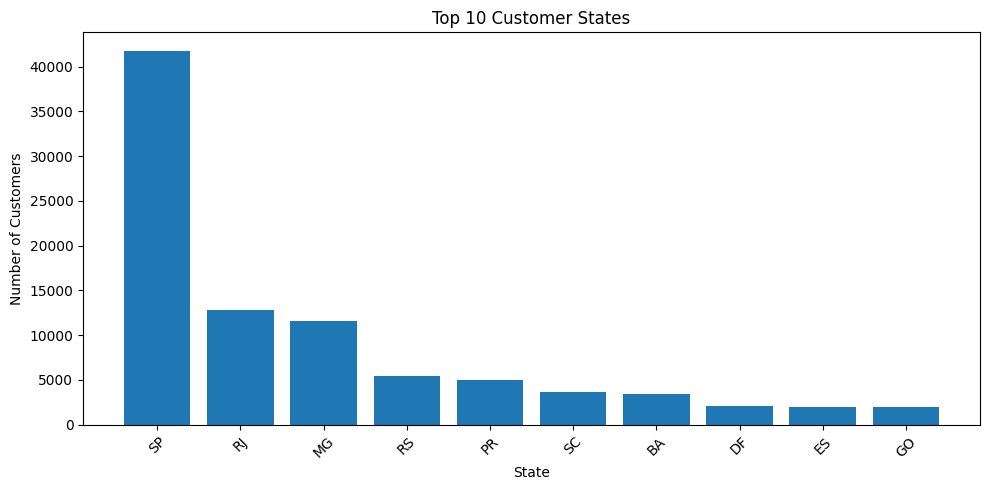

In [52]:

query = """
SELECT
customer_state,
COUNT(*) AS num_customers
FROM customers
GROUP BY customer_state
ORDER BY num_customers DESC
LIMIT 10
"""

state_top10 = pd.read_sql(query, conn)

display(state_top10)

# Create a bar chart
plt.figure(figsize=(10, 5))
plt.bar(
state_top10['customer_state'],
state_top10['num_customers']
)

plt.title('Top 10 Customer States')
plt.xlabel('State')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

---

## Question 8: Monthly order trend (line chart)

**Your task:**
1. From the cleaned `orders` DataFrame (with datetime columns from Q2), extract a `year_month` period from `order_purchase_timestamp` using `.dt.to_period('M')`
2. Count orders per month — save to a DataFrame called `monthly_orders` with columns `year_month` and `num_orders`
3. Plot a **line chart** of `num_orders` over time. Add a title.

**Hint:** `orders['order_purchase_timestamp'].dt.to_period('M').value_counts().sort_index()` is a fast way to get monthly counts. Convert the period index back to string for plotting.

*Skills: Sprint 4 Ch 02 (datetime), Ch 03 (groupby), Ch 04 (line chart)*

,year_month,num_orders
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780
5,2017-03,2682
6,2017-04,2404
7,2017-05,3700
8,2017-06,3245
9,2017-07,4026


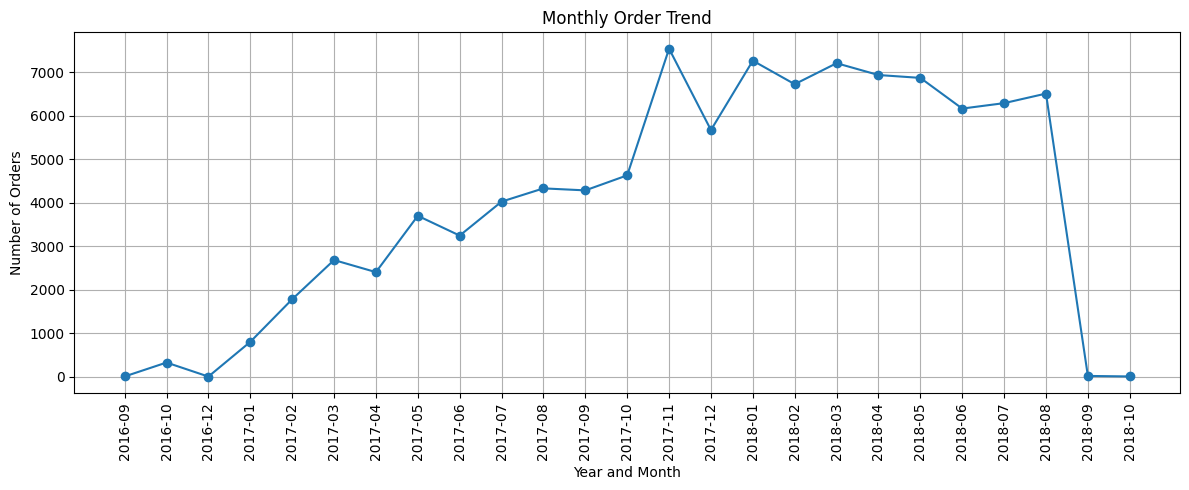

In [53]:
monthly_orders = (
orders['order_purchase_timestamp']
.dt.to_period('M')
.value_counts()
.sort_index()
.reset_index()
)

monthly_orders.columns = ['year_month', 'num_orders']

# Convert dates to strings
monthly_orders['year_month'] = (
monthly_orders['year_month'].astype(str)
)

display(monthly_orders)

# Create a line chart
plt.figure(figsize=(12, 5))

plt.plot(
monthly_orders['year_month'],
monthly_orders['num_orders'],
marker='o'
)

plt.title('Monthly Order Trend')
plt.xlabel('Year and Month')
plt.ylabel('Number of Orders')
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()



---

## Question 9: Does delivery speed affect review scores?

This is a real business question: do customers who get their orders faster leave better reviews?

**Your task:**
1. From `orders`, keep only rows where `order_delivered_customer_date` is not null
2. Add a `delivery_days` column = (delivery date − purchase date) in days. **Hint:** subtract the two datetime columns and use `.dt.days`
3. Merge with `reviews` on `order_id` to get the `review_score` for each order
4. Compute the **correlation** between `delivery_days` and `review_score` using `.corr()`
5. Group by `review_score` and show the **average delivery days** for each score (1 through 5)
6. Plot a bar chart of average delivery days by review score

What pattern do you see? Add a markdown cell with your interpretation.

*Skills: Sprint 4 Ch 03 (correlation), Ch 04 (visualization), Ch 06 (merge + groupby)*

Correlation: -0.334


,review_score,delivery_days
0,1,20.849825
1,2,16.194832
2,3,13.795278
3,4,11.848054
4,5,10.224097


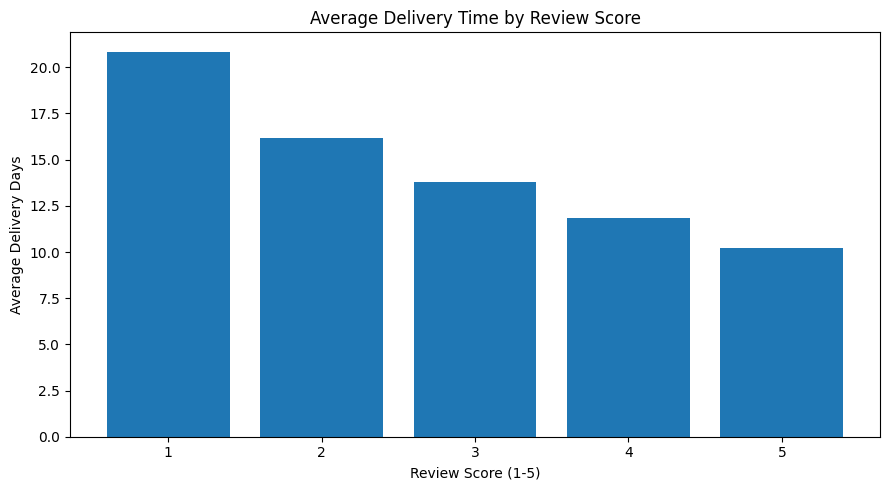

In [54]:
# 1. Keep only delivered orders
delivery_df = orders.dropna(
subset=['order_delivered_customer_date']
).copy()

# 2. Calculate delivery time in days
delivery_df['delivery_days'] = (
delivery_df['order_delivered_customer_date']
- delivery_df['order_purchase_timestamp']
).dt.days

# 3. Merge with review scores
delivery_df = delivery_df.merge(
reviews[['order_id', 'review_score']],
on='order_id',
how='inner'
)

# 4. Calculate correlation
correlation = delivery_df[
['delivery_days', 'review_score']
].corr().loc['delivery_days', 'review_score']

print("Correlation:", round(correlation, 3))

# 5. Average delivery days by review score
delivery_summary = (
delivery_df.groupby('review_score')['delivery_days']
.mean()
.reset_index()
)

display(delivery_summary)

# 6. Create bar chart
plt.figure(figsize=(9, 5))

plt.bar(
delivery_summary['review_score'],
delivery_summary['delivery_days']
)

plt.title('Average Delivery Time by Review Score')
plt.xlabel('Review Score (1-5)')
plt.ylabel('Average Delivery Days')
plt.xticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()


**Your interpretation:**
The analysis shows a negative relationship between delivery time and customer review scores. Orders rated 1 star took an average of 20.85 days to arrive, compared with only 10.22 days for orders rated 5 stars. This suggests that faster deliveries are associated with higher customer satisfaction, making delivery efficiency an important area for business improvement.

---

## Question 10: Final Report

Write a **2–3 paragraph executive summary** of your findings as a markdown cell below. A good report answers:

- **What is the overall health of the business?** (Use Q3, Q8 — order volumes and trends)
- **Which product categories should we double down on?** (Use Q6 — revenue + review scores together)
- **Where are our customers and how do we serve them?** (Use Q7, Q9 — geography and delivery speed)
- **What is one specific recommendation you would make to the leadership team?**

Write as if you're presenting to a non-technical executive. Use plain language. Reference specific numbers from your analysis.

*Skills: Sprint 4 Ch 06 (analytical reporting)*

## Executive Summary

### Business Health
The Brazilian e-commerce business demonstrates strong order fulfillment performance, with 97.02% of 99,441 orders marked as delivered. Order volume increased significantly throughout 2017 and remained relatively stable at approximately 6,000–7,300 orders per month during much of 2018. The sharp decline in September and October 2018 likely reflects incomplete data rather than a confirmed business downturn.



### Top Categories

Health & Beauty is the leading category by calculated revenue, generating approximately BRL 1.44 million with an average customer review score of 4.14 out of 5. Watches & Gifts follows with approximately BRL 1.31 million and a 4.02 average rating. Bed, Bath & Table also generates substantial revenue, approximately BRL 1.24 million, but has a lower average rating of 3.90, suggesting an opportunity to improve customer satisfaction.
### Customer Geography & Delivery

São Paulo is the largest customer market, representing approximately 42% of customer records, followed by Rio de Janeiro and Minas Gerais. Delivery speed is associated with customer satisfaction: orders rated 5 stars arrived in an average of 10.22 days, compared with 20.85 days for orders rated 1 star. I recommend prioritizing faster and more reliable delivery, especially in major customer markets, while maintaining investment in high-performing categories such as Health & Beauty. Improving delivery performance and monitoring customer reviews could strengthen customer satisfaction and support future growth.

